# Monthly Price decomposition — Population (pop) path · rolling year-over-year

**Fitness = firm-count growth $n'/n$; trait = $\log(\text{real total sales})$; rebalanced Price machinery** (the headline path). Built on the master driver's **rolling 12-month** run: each window compares a month to the *same month one year earlier* (2019M04→2020M04, …), stepped monthly → 72 points, 2018M01–2023M12. Both ends share a calendar month, so **seasonality cancels** and each value is a genuine **per-year** rate — no ×12 annualisation artifact. COVID appears as the year-over-year real-sales collapse in the windows ending across 2020.

In [1]:
# ==============================================================================
# MONTHLY PRICE DECOMPOSITION -- rolling 12-month (year-over-year) time series
# ------------------------------------------------------------------------------
# Same engine + hierarchy (parish < canton < province + country rollup) as the
# quarterly notebook, read at the MONTHLY grain from the driver's ROLLING
# run:  results/decomposition/monthly_rolling12_2017_2023/
# Each window compares a month to the SAME month one year earlier (2019M04 vs
# 2020M04, ...), advancing one month at a time -> 72 points, 2018M01 .. 2023M12.
# Because both ends are the same calendar month, SEASONALITY CANCELS and every
# term is a genuine PER-YEAR rate (elapsed = 1 yr; no 1/12 blow-up). A point
# dated "Apr '20" is the 12-month change ending April 2020.
#
# This notebook covers ONE decomposition path; set PATH below. The three path
# notebooks share these cells verbatim -- only PATH differs:
#   pop  firm-count growth (fitness) x log(real sales)  (trait)  [rebalanced Price]
#   inc  real-sales growth (fitness) x real-sales level (trait)  [Olley-Pakes]
#   den  firm-count growth (fitness) x firm count       (trait)  [Olley-Pakes]
# ==============================================================================
import calendar
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PATH = "pop"     # <-- the only line that differs between the three notebooks

# The project root is the folder that holds ecuador_price/ (this notebook lives in notebooks/).
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "ecuador_price").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))
from ecuador_price import decomposition as dec, paths, style
style.apply()                      # the project's fonts and colours

MASTER_DIR = paths.decomposition_run("monthly_rolling12_2017_2023")
PLOTS_DIR = MASTER_DIR / "plots"
PLOTS_DIR.mkdir(exist_ok=True)

# Per-path labels/colours used by every figure below.
PATH_META = {
    "pop": dict(name="Firm Attraction to Revenue",
                fitness="firm-count growth  n'/n", trait="log(real total sales)",
                trans="Transmission  (within-region real-sales growth)",
                sel="Selection  (spatial sorting of firm formation)",
                unit="log points"),
    "inc": dict(name="Revenue concentration",
                fitness="real-sales log growth", trait="real-sales level",
                trans="Transmission  (within-region real-sales growth)",
                sel="Selection  (sales reallocated toward growing regions)",
                unit="log points"),
    "den": dict(name="Firm Concentration",
                fitness="firm-count log growth", trait="firm count  n",
                trans="Transmission  (within-region firm-count growth)",
                sel="Selection  (experienced-density drift)",
                unit="percentage"),
}
META = PATH_META[PATH]
TRANS_COLOR, SEL_COLOR = style.RED, style.BLUE
STRIDE = 3   # label every 3rd month so the 72-point axis stays legible

summary = pd.read_csv(MASTER_DIR / "decomposition_summary.csv")
df = summary[summary["path"] == PATH].copy()


def month_label(period):                       # "2020M04" -> "Apr '20"
    return f"{calendar.month_abbr[int(period[5:])]} '{period[2:4]}"


# The 72 rolling YoY windows in chronological order, each DATED AT ITS END month
# (so "Apr '20" is the Apr 2019 -> Apr 2020 change). Months are zero padded, so
# a plain string sort on initial_period is already chronological.
ts = (df[df["window_type"] == "step"]
      .sort_values("initial_period").reset_index(drop=True))
labels = [month_label(p) for p in ts["final_period"]]
xs = list(range(len(ts)))

# COVID: the YoY window ending Apr 2020 is the onset trough; every window ending
# from Apr 2020 to Apr 2021 still straddles the 2020 lockdown -> shade that band.
covid_pos = int(ts.index[ts["final_period"] == "2020M04"][0])
covid_end = int(ts.index[ts["final_period"] == "2021M04"][0])

head = df[df["window_type"] == "headline"].iloc[0]
print(f"PATH = {PATH!r}  ({META['name']})")
print(f"  fitness = {META['fitness']}   |   trait = {META['trait']}")
print(f"  {len(ts)} rolling 12-month windows, "
      f"{ts['final_period'].iloc[0]} .. {ts['final_period'].iloc[-1]}")
print()
print(f"season-matched headline {head['initial_period']}->{head['final_period']} "
      f"(per year over {head['elapsed_years']:.0f} yr):")
print(f"  selection_total = {head['selection_total']:+.4f}")
print(f"  transmission    = {head['transmission']:+.4f}")
print(f"  delta_trait/yr  = {head['delta_trait_per_year']:+.4f}")
print()
print("COVID onset window (ends Apr 2020):")
c = ts.loc[covid_pos]
print(f"  {c['initial_period']}->{c['final_period']}: "
      f"selection {c['selection_total']:+.3f}, transmission {c['transmission']:+.3f} "
      f"({np.expm1(c['transmission']):+.0%} YoY)")


PATH = 'pop'  (Firm Attraction to Revenue)
  fitness = firm-count growth  n'/n   |   trait = log(real total sales)
  72 rolling 12-month windows, 2018M01 .. 2023M12

season-matched headline 2017M01->2023M01 (per year over 6 yr):
  selection_total = -0.0428
  transmission    = +0.0507
  delta_trait/yr  = +0.0079

COVID onset window (ends Apr 2020):
  2019M04->2020M04: selection +0.077, transmission -0.616 (-46% YoY)


## Selection — spatial sorting of firm formation

Selection = covariance across regions between firm-count growth and *initial* log-sales. **Negative ⇒ dispersion** (firms grow fastest where sales start low — spatial catch-up); **positive ⇒ re-concentration**. Note the brief flip to *positive* during the 2020 windows: the collapse hit the low-sales periphery hardest, temporarily re-concentrating activity.

## Spike months — where the series does something, and who did it

The 72-point series is mostly a band of ordinary months punctuated by a handful of episodes. The cell below finds them mechanically — a **robust z-score** (deviation from the series median in MAD units, so the COVID outliers don't inflate their own yardstick) flags every month where selection or transmission leaves its normal band — and then attributes each *selection* spike to provinces by recomputing the between-province covariance from that window's exported parish table (`parish_parish_exported_terms.csv`, verified to match the summary exactly).

The episodes it finds, in calendar order:

1. **May–Jul 2019 — a selection dive with no transmission event** (S ≈ −0.11 at May '19). Between-province selection triples for three windows: a broad burst of firm formation across *small* provinces (Zamora Chinchipe, Sucumbíos, Cañar…) while Guayas lagged — dispersion at its strongest, a year *before* COVID.
2. **Oct 2019 — transmission blips negative** (−0.055): the only autumn-2019 window to fall below zero; it is the 12-month window that contains the October 2019 *paro nacional* (fuel-subsidy protests that shut the country for ~2 weeks).
3. **Mar–Jul 2020 — the COVID shock**: transmission collapses (−0.62 at Apr '20, the largest |value| anywhere in the series) while selection flips positive (+0.11 at May '20) — the monthly-resolution version of the flip dissected in the seasonal notebook.
4. **Mar–May 2021 — the mirror-image base effect**: transmission +0.58 at Apr '21 because the *comparison month* is the 2020 trough. Not a boom — an echo.
5. **Oct 2022–Mar 2023 — a second selection dive** (S ≈ −0.15 at Dec '22), again led by between-provinces (Guayas, Pichincha) — the metros resumed lagging hard.
6. **Oct–Dec 2023 — selection turns positive again** (+0.08), led by Guayas and Pichincha *plus Esmeraldas*, whose firm formation collapsed amid the 2023 security crisis (a small province under-growing pushes S *up*).

## The October-2022 shift: parishes-within-cantons decouples and turns positive

In the scale-split figure the **parishes-within-cantons** component tracks the (negative) cantons-within-provinces line for most of the series — then from the window ending **Oct 2022** it breaks away and stays *positive* through 2023, while the other two components dive negative. The cell below opens that component up: the engine already exports, for every window, each canton's *internal* parish-level selection (`Sel_canton_from_parish_pop` in `parish_canton_exported_terms.csv`), and the national component is exactly the **final-firm-share-weighted sum** of those canton values (verified below to machine precision). So we can watch each canton's within-canton covariance through time and ask *which cantons flipped*.

### What flipped in October 2022 — re-concentration toward canton cores, minus Quito

The decomposition of the flip is clean:

- **Who pushed it positive:** the cantons of the *mid-size provincial capitals* — **Cuenca (+2.0 ×10⁻³ shift), Ambato (+1.7), Portoviejo, Azogues, Santa Rosa** — plus the Amazon oil cantons **Orellana (+1.4) and Pastaza (+0.8)**. Inside those cantons, from late 2022 the high-revenue *core parish* started adding firms faster than its own periphery (or the periphery began under-growing) — a within-canton version of the COVID concentration pattern, but persistent rather than a one-year shock.
- **Who pushed the other way: Quito (−2.4 ×10⁻³).** Inside the DMQ canton the opposite happened — the peripheral parishes out-grew the core, so Quito's *internal* selection went more negative even as it dominated the earlier flip at the national scale. Concentration between cantons, dispersion inside the capital.
- The remaining ~200 cantons ("total minus the four movers") drift mildly positive too, so this is a broad tilt led by identifiable places, not a single-canton artifact.

Read together with the seasonal notebook's decile chart (where 2022→23 shows small/mid size-deciles contributing *positively* again), the post-Oct-2022 period looks like a **partial echo of the COVID configuration operating at the finest scale**: formal-firm formation in provincial Ecuador re-concentrating toward canton seats, while the giant metros lag between cantons and disperse internally. Worth re-testing when 2024 data arrive; note also that windows ending late 2022 compare against the strong 2021-rebound base, so part of the level shift is base effect — the *cross-canton pattern*, however, is not.

## How to read the numbers — units

Every term obeys the Price identity **Δ trait = selection + transmission**, and every value is a **per-year** rate. Because each point is a rolling 12-month window (same calendar month a year apart), **seasonality cancels** and the elapsed time is exactly 1 year — so the numbers are honest annual growth rates with none of the ×12 blow-up that ruined the consecutive-month version. For $|\text{value}|\lesssim0.1$, log points ≈ %; larger moves convert exactly with $e^x-1$ (the COVID trough transmission ≈ $-0.62$ ⇒ $e^{-0.62}-1\approx-46\%$ real sales year-over-year). **Dating:** a point at 'Apr 20' is the change from Apr 2019 to Apr 2020. To change the horizon (e.g. rolling quarters), set `WINDOW_HORIZON` in `run_ecuador_price_decomposition_master.py` and re-run.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# ==============================================================================
# Shared styling
# ==============================================================================
plt.rcParams.update({
    "font.family":      "STIXGeneral",
    "mathtext.fontset": "cm",
    "axes.titlesize":   14,
    "axes.labelsize":   13,
    "xtick.labelsize":  11,
    "ytick.labelsize":  11,
    "axes.linewidth":   1.1,
    "axes.edgecolor":   "black",
})

COVID_C = style.RED


def get_ts(path):
    """Chronological step windows for one path + the two COVID band indices."""
    d = (summary[(summary["path"] == path) & (summary["window_type"] == "step")]
         .sort_values("initial_period")
         .reset_index(drop=True))
    c0 = int(d.index[d["final_period"] == "2020M04"][0])   # onset trough
    c1 = int(d.index[d["final_period"] == "2021M04"][0])   # last window spanning 2020
    return d, c0, c1


# ==============================================================================
# Automatic label placement -- used by EVERY figure in this notebook
# ------------------------------------------------------------------------------
# The value labels used to sit at a fixed offset from their point, so they landed
# on top of the plotted lines, on each other, or on the "COVID" tag at the top of
# the red band. Now each label is TRIED at a handful of candidate offsets around
# its point and the least-colliding one wins. Obstacles: the plotted lines, every
# text already on the axes (the COVID tag, and any label placed before this one),
# the legend, and the axes frame itself.
# ==============================================================================
_CAND_DY = (0, 16, -16, 30, -30, 46, -46)      # vertical nudges, in points


def _bbox_overlap(a, b):
    """Overlapping area of two display-space bboxes (0 if they miss)."""
    dx = min(a.x1, b.x1) - max(a.x0, b.x0)
    dy = min(a.y1, b.y1) - max(a.y0, b.y0)
    return dx * dy if dx > 0 and dy > 0 else 0.0


def _line_points(ax):
    """Every plotted vertex, densified along each segment, in display coords."""
    out = []
    for ln in ax.get_lines():
        if ln.get_transform() is not ax.transData:      # skips axhline & friends
            continue
        xy = ln.get_xydata()
        if len(xy) < 2:
            continue
        fine = np.concatenate([xy[:-1] + f * (xy[1:] - xy[:-1])
                               for f in np.linspace(0, 1, 6)])
        out.append(ax.transData.transform(fine))
    return np.concatenate(out) if out else np.empty((0, 2))


def _place_label(ax, pos, v, text, color, ann_fs, right_only):
    """Draw one label near (pos, v), at whichever offset collides least."""
    fig = ax.figure
    fig.canvas.draw()                          # text sizes need a live renderer
    rend = fig.canvas.get_renderer()

    pts = _line_points(ax)
    obstacles = [t.get_window_extent(rend) for t in ax.texts]
    leg = ax.get_legend()
    if leg is not None:
        obstacles.append(leg.get_window_extent(rend))
    frame = ax.get_window_extent(rend)

    probe = ax.annotate(text, (pos, v), textcoords="offset points",
                        xytext=(10, 0), va="center", fontsize=ann_fs,
                        fontweight="bold", annotation_clip=False)

    def cost(bb):
        pad = bb.expanded(1.10, 1.6)           # a little breathing room
        on_line = ((pts[:, 0] > pad.x0) & (pts[:, 0] < pad.x1) &
                   (pts[:, 1] > pad.y0) & (pts[:, 1] < pad.y1)).sum()
        outside = bb.width * bb.height - _bbox_overlap(bb, frame)
        return (4.0 * on_line                                       # over a line
                + sum(_bbox_overlap(pad, ob) for ob in obstacles) / 60.0
                + outside / 30.0)                                   # off the axes

    best = None
    for dx in ((10,) if right_only else (10, -10)):
        for dy in _CAND_DY:
            probe.set_position((dx, dy))
            probe.set_ha("left" if dx > 0 else "right")
            c = cost(probe.get_window_extent(rend)) + 0.02 * abs(dy)  # stay close
            if best is None or c < best[0]:
                best = (c, dx, dy)
    probe.remove()

    _, dx, dy = best
    ax.annotate(
        text, (pos, v),
        textcoords="offset points", xytext=(dx, dy),
        ha="left" if dx > 0 else "right", va="center",
        fontsize=ann_fs, fontweight="bold", color=color, zorder=6,
        annotation_clip=False,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.80, pad=1.0),
        # hairline leader only when the label had to walk away from its point
        arrowprops=(dict(arrowstyle="-", lw=0.6, color=color, shrinkA=0, shrinkB=3)
                    if abs(dy) > 16 else None),
    )


def annotate_band_minmax(ax, d, c0, c1, col, color, ann_fs=10, right_only=False):
    """
    Label the min and max of `col` inside the COVID band, placed so the text
    clears the lines, the COVID tag and any label already on this axes.
    Call it LAST -- after the lines, the COVID tag and the legend exist.
    `right_only=True` keeps labels on the right-hand side of their point.
    """
    band = d.loc[c0:c1]
    i_min = int(band[col].idxmin())
    i_max = int(band[col].idxmax())

    points = [(i_min, float(d.loc[i_min, col]))]
    if i_max != i_min:
        points.append((i_max, float(d.loc[i_max, col])))

    for pos, v in points:
        _place_label(ax, pos, v, f"{v:+.2f} ({np.expm1(v):+.0%})",
                     color, ann_fs, right_only)


def add_headroom(ax, top=0.16, bottom=0.05):
    """Widen the y-range so the COVID tag and the labels have somewhere to go."""
    y0, y1 = ax.get_ylim()
    span = y1 - y0
    ax.set_ylim(y0 - bottom * span, y1 + top * span)


def draw_panel(ax, path, tick_stride, small=False, show_xticklabels=True,
               show_legend=True, legend_loc="upper left"):
    ann_fs, tick_fs, leg_fs = (9, 10, 9.5) if small else (10, 11, 11)

    meta = PATH_META[path]
    d, c0, c1 = get_ts(path)
    xs = list(range(len(d)))
    labels = [month_label(p) for p in d["final_period"]]

    ax.axhline(0, color="0.35", lw=1.0, alpha=0.40, zorder=1)
    ax.axvspan(c0 - 0.5, c1 + 0.5, color=COVID_C, alpha=0.08, zorder=0)

    ax.plot(xs, d["transmission"], marker="o", ms=3, lw=1.6,
            color=TRANS_COLOR, label=meta["trans"], zorder=3)
    ax.plot(xs, d["selection_total"], marker="s", ms=3, lw=1.6,
            color=SEL_COLOR, label=meta["sel"], zorder=3)

    ax.set_xticks(xs[::tick_stride])
    ax.set_xticklabels(labels[::tick_stride], rotation=90, fontsize=tick_fs)
    if not show_xticklabels:
        ax.tick_params(labelbottom=False)

    ax.set_ylabel(meta["unit"])
    ax.set_title(meta["name"].split("(")[0].strip())

    if show_legend:
        leg = ax.legend(loc=legend_loc, fontsize=leg_fs, frameon=True,
                        fancybox=False, edgecolor="black", framealpha=1.0,
                        handlelength=1.2, handletextpad=0.6,
                        borderpad=0.5, labelspacing=0.35)
        leg.get_frame().set_linewidth(0.9)

    # COVID tag and value labels go last: the placer needs the lines, the tag
    # and the legend to already be on the axes so it can dodge them.
    add_headroom(ax)
    ax.text((c0 + c1) / 2, ax.get_ylim()[1], "COVID",
            ha="center", va="top", fontsize=ann_fs,
            fontweight="bold", color=COVID_C)

    annotate_band_minmax(ax, d, c0, c1, "transmission", TRANS_COLOR, ann_fs=ann_fs)
    annotate_band_minmax(ax, d, c0, c1, "selection_total", SEL_COLOR, ann_fs=ann_fs)

saved -> monthly_timeseries_pop.png


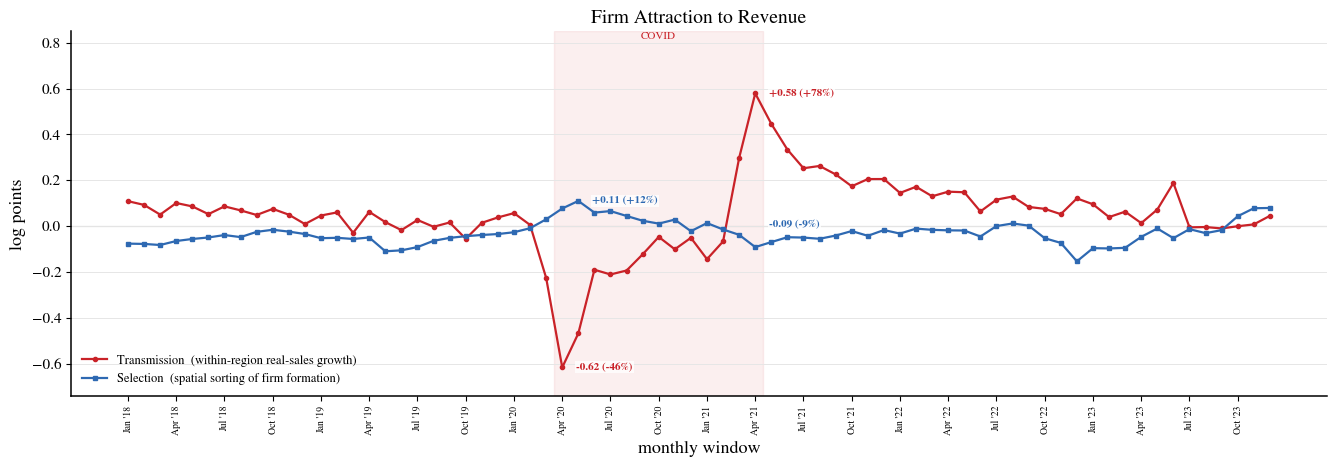

In [3]:
path = PATH   # or "pop", "inc", "den"
ts, covid_pos, covid_end = get_ts(path)
xs = list(range(len(ts)))
labels = [month_label(p) for p in ts["final_period"]]

fig, ax = plt.subplots(figsize=(13.5, 4.8))
ax.axhline(0, color="0.7", lw=0.8, zorder=1)
ax.axvspan(covid_pos - 0.5, covid_end + 0.5, color=style.RED, alpha=0.07, zorder=0)

ax.plot(xs, ts["transmission"], marker="o", ms=3, lw=1.6,
        color=TRANS_COLOR, label=META["trans"], zorder=3)
ax.plot(xs, ts["selection_total"], marker="s", ms=3, lw=1.6,
        color=SEL_COLOR, label=META["sel"], zorder=3)

ax.set_xticks(xs[::STRIDE])
ax.set_xticklabels(labels[::STRIDE], rotation=90, fontsize=7)
ax.set_ylabel(META["unit"])
ax.set_xlabel("monthly window")
ax.set_title(f"Firm Attraction to Revenue")
ax.grid(axis="y", color="0.9", lw=0.7)

for s in ("top", "right"):
    ax.spines[s].set_visible(False)

ax.legend(loc="lower left", frameon=False, fontsize=9)

# COVID tag + value labels last, so the placer can dodge lines, tag and legend
add_headroom(ax)
ax.text((covid_pos + covid_end) / 2, ax.get_ylim()[1],
        "COVID",
        ha="center", va="top", fontsize=8, color=style.RED)

right_only = path in ("pop", "inc")
annotate_band_minmax(ax, ts, covid_pos, covid_end, "transmission", TRANS_COLOR, ann_fs=8, right_only=right_only)
annotate_band_minmax(ax, ts, covid_pos, covid_end, "selection_total", SEL_COLOR, ann_fs=8, right_only=right_only)

fig.tight_layout()
fig.savefig(PLOTS_DIR / f"monthly_timeseries_{PATH}.png", dpi=200, bbox_inches="tight")
fig.savefig(PLOTS_DIR / f"monthly_timeseries_{PATH}.pdf", bbox_inches="tight")
fig.savefig(PLOTS_DIR / f"monthly_timeseries_{PATH}.svg", bbox_inches="tight")
print(f"saved -> monthly_timeseries_{PATH}.png")
plt.show()

saved -> monthly_timeseries_all_paths.png / .pdf / .svg


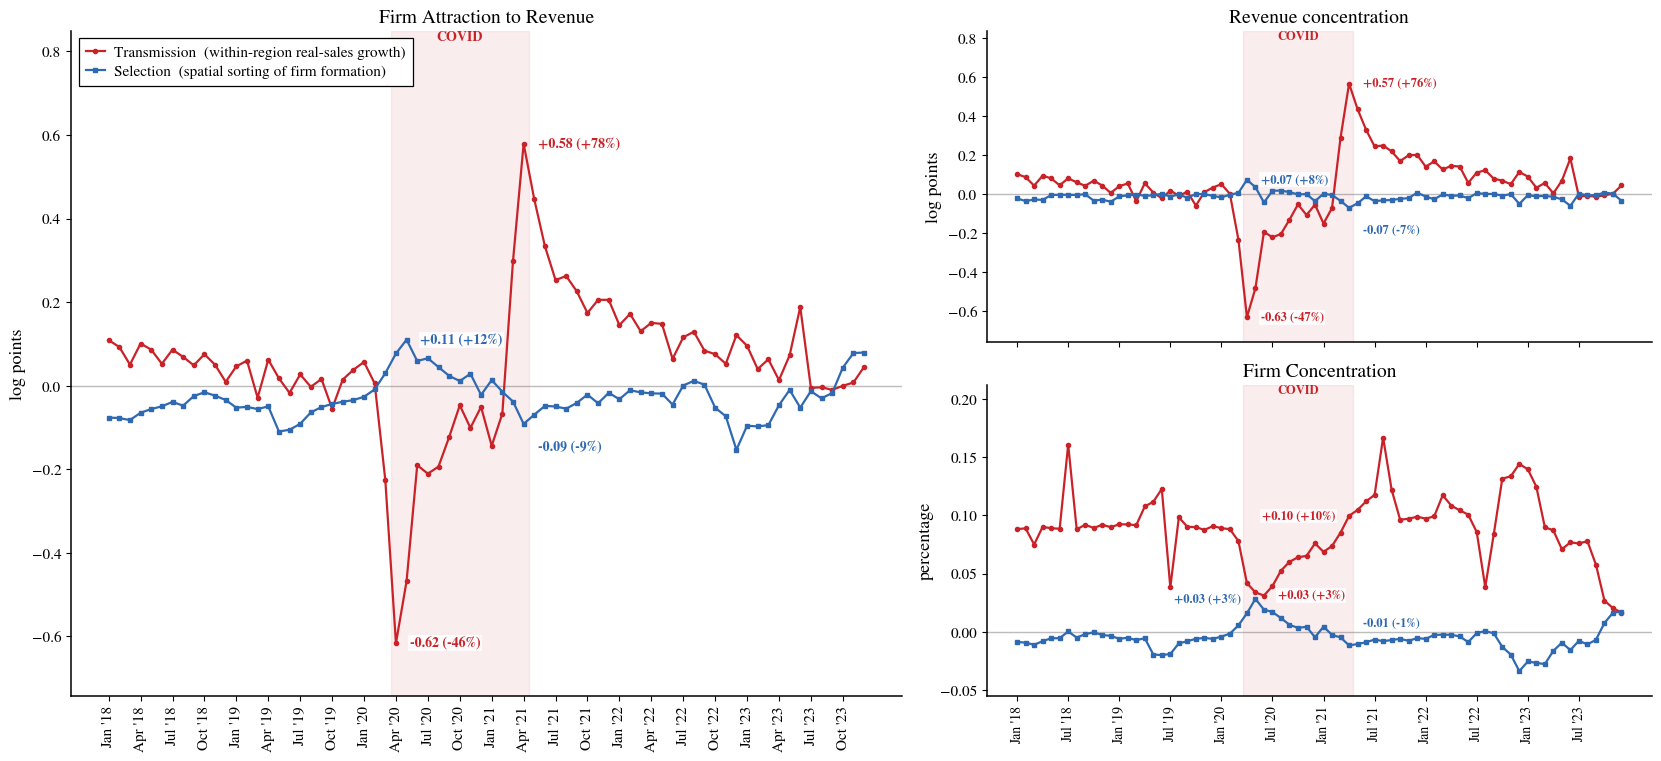

In [4]:
fig, axes = plt.subplot_mosaic(
    [["pop", "inc"],
     ["pop", "den"]],
    figsize=(16.5, 7.5),
    gridspec_kw={"width_ratios": [1.25, 1]},
    constrained_layout=True
)

draw_panel(axes["pop"], "pop", tick_stride=STRIDE,
           show_legend=True, legend_loc="upper left")

draw_panel(axes["inc"], "inc", tick_stride=2 * STRIDE,
           small=True, show_xticklabels=False, show_legend=False)

draw_panel(axes["den"], "den", tick_stride=2 * STRIDE,
           small=True, show_legend=False)

out = "monthly_timeseries_all_paths"
fig.savefig(PLOTS_DIR / f"{out}.png", dpi=200, bbox_inches="tight")
fig.savefig(PLOTS_DIR / f"{out}.pdf", bbox_inches="tight")
fig.savefig(PLOTS_DIR / f"{out}.svg", bbox_inches="tight")
print(f"saved -> {out}.png / .pdf / .svg")
plt.show()

saved -> monthly_timeseries_all_selection_paths.png / .pdf / .svg


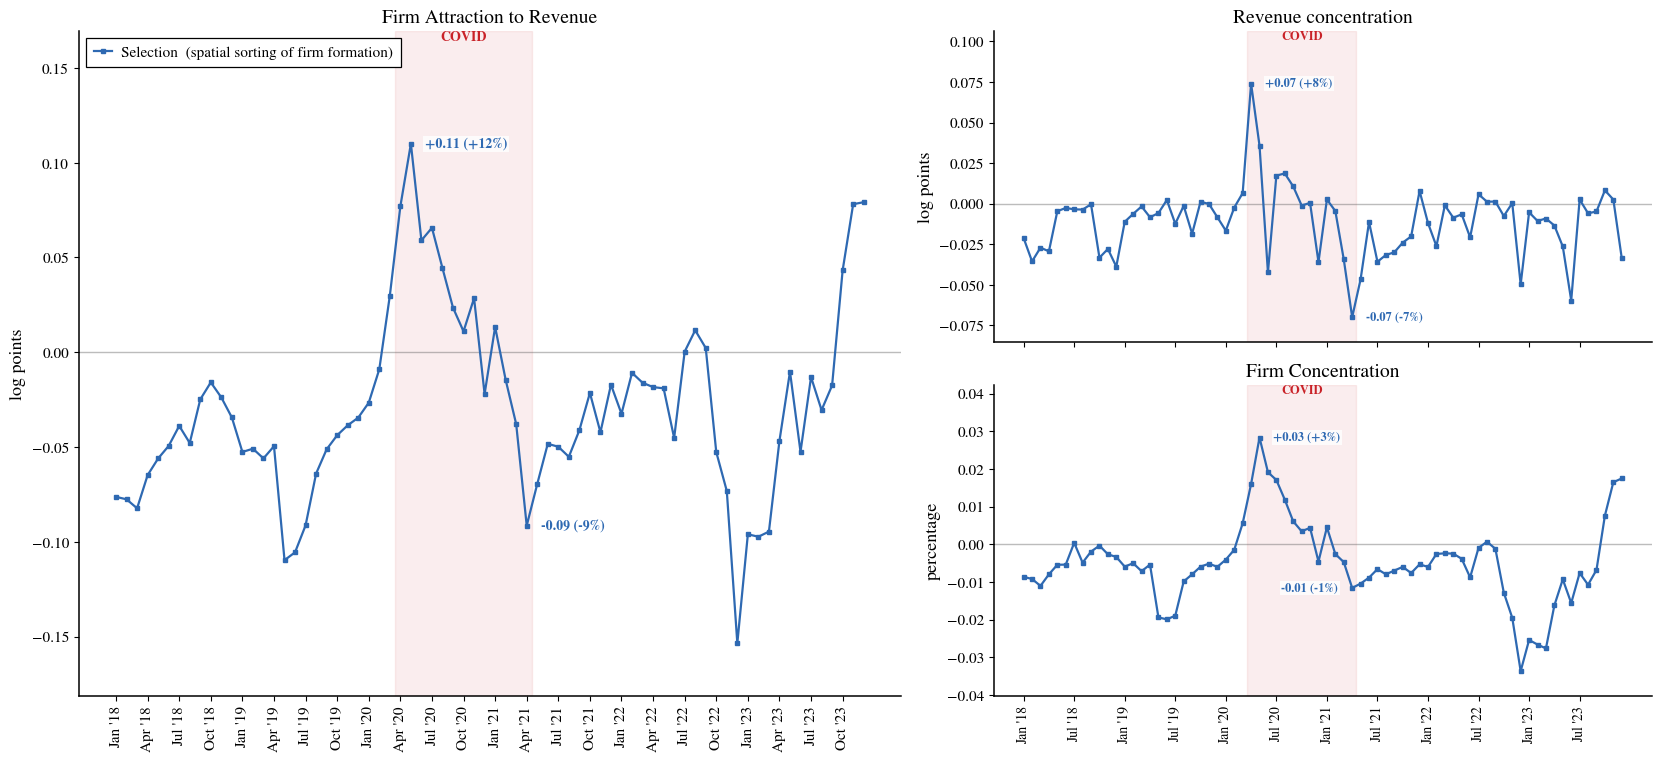

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Selection-only version of the mosaic above. get_ts / annotate_band_minmax /
# add_headroom come from the shared styling cell earlier in this notebook.


def draw_sel_panel(ax, path, tick_stride, small=False, show_xticklabels=True,
                   show_legend=True, legend_loc="upper left"):
    ann_fs, tick_fs, leg_fs = (9, 10, 9.5) if small else (10, 11, 11)

    meta = PATH_META[path]
    d, c0, c1 = get_ts(path)
    xs = list(range(len(d)))
    labels = [month_label(p) for p in d["final_period"]]

    ax.axhline(0, color="0.35", lw=1.0, alpha=0.40, zorder=1)
    ax.axvspan(c0 - 0.5, c1 + 0.5, color=COVID_C, alpha=0.08, zorder=0)

    # Only selection_total
    ax.plot(xs, d["selection_total"], marker="s", ms=3, lw=1.6,
            color=SEL_COLOR, label=meta["sel"], zorder=3)

    ax.set_xticks(xs[::tick_stride])
    ax.set_xticklabels(labels[::tick_stride], rotation=90, fontsize=tick_fs)
    if not show_xticklabels:
        ax.tick_params(labelbottom=False)

    ax.set_ylabel(meta["unit"])
    ax.set_title(meta["name"].split("(")[0].strip())

    if show_legend:
        leg = ax.legend(loc=legend_loc, fontsize=leg_fs, frameon=True,
                        fancybox=False, edgecolor="black", framealpha=1.0,
                        handlelength=1.2, handletextpad=0.6,
                        borderpad=0.5, labelspacing=0.35)
        leg.get_frame().set_linewidth(0.9)

    # COVID tag + value labels last, so the placer can dodge them
    add_headroom(ax)
    ax.text((c0 + c1) / 2, ax.get_ylim()[1], "COVID",
            ha="center", va="top", fontsize=ann_fs,
            fontweight="bold", color=COVID_C)

    annotate_band_minmax(ax, d, c0, c1, "selection_total", SEL_COLOR, ann_fs=ann_fs)


fig, axes = plt.subplot_mosaic(
    [["pop", "inc"],
     ["pop", "den"]],
    figsize=(16.5, 7.5),
    gridspec_kw={"width_ratios": [1.25, 1]},
    constrained_layout=True
)

draw_sel_panel(axes["pop"], "pop", tick_stride=STRIDE,
               show_legend=True, legend_loc="upper left")

draw_sel_panel(axes["inc"], "inc", tick_stride=2 * STRIDE,
               small=True, show_xticklabels=False, show_legend=False)

draw_sel_panel(axes["den"], "den", tick_stride=2 * STRIDE,
               small=True, show_legend=False)

out = "monthly_timeseries_all_selection_paths"
fig.savefig(PLOTS_DIR / f"{out}.png", dpi=200, bbox_inches="tight")
fig.savefig(PLOTS_DIR / f"{out}.pdf", bbox_inches="tight")
fig.savefig(PLOTS_DIR / f"{out}.svg", bbox_inches="tight")
print(f"saved -> {out}.png / .pdf / .svg")
plt.show()

saved -> monthly_selection_components_all_paths.png


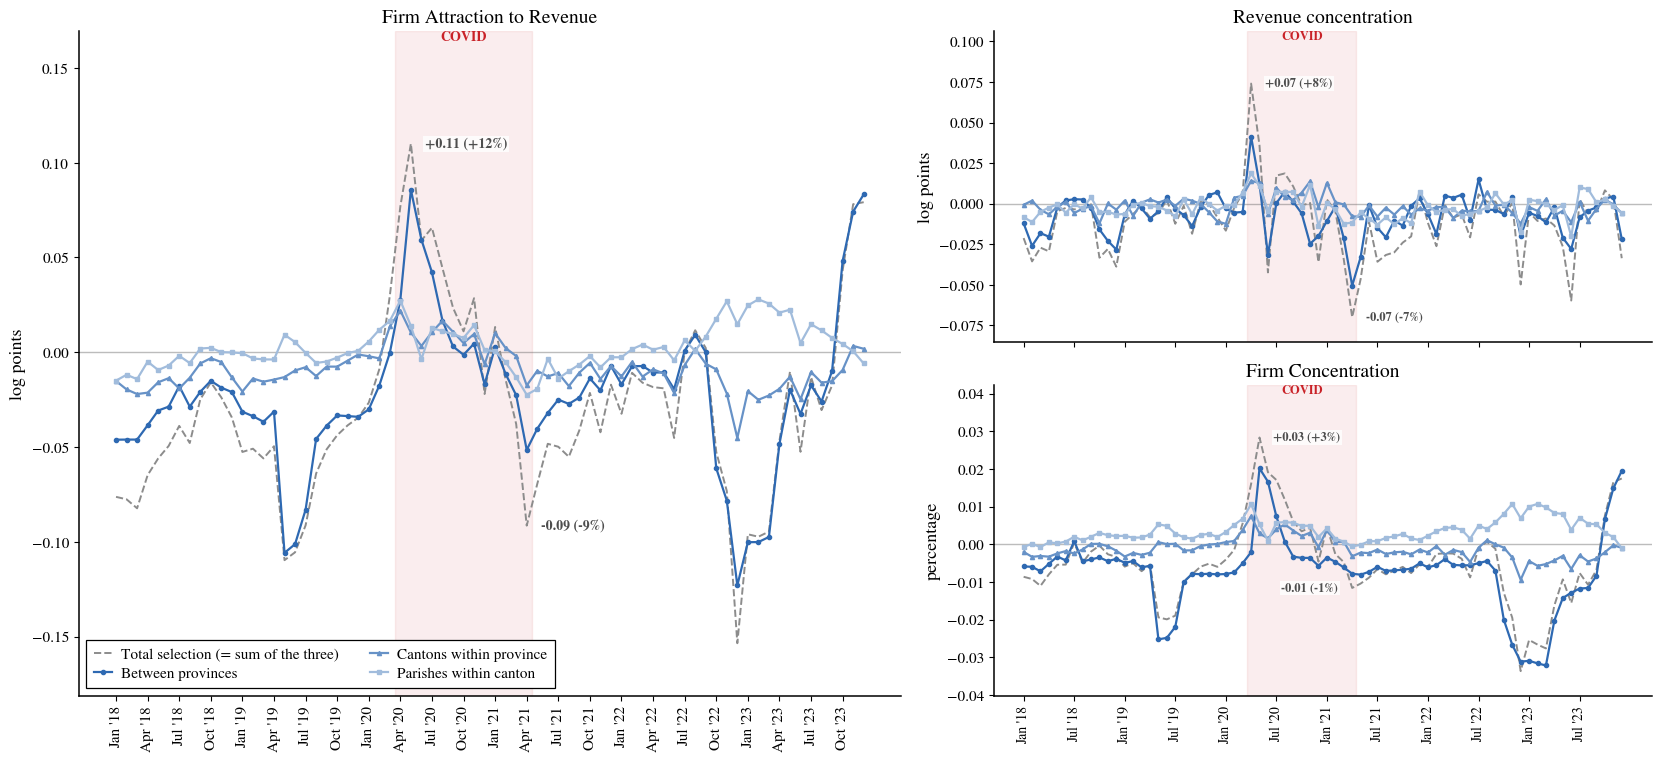

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Selection split by spatial scale -- same panel furniture as the two mosaics
# above (framed legend, no grid, full axes frame, short titles, COVID tag last).
# get_ts / annotate_band_minmax / add_headroom come from the shared styling cell.

SEL_COMPONENTS = [
    ("sel_between_provinces",      style.BLUE, "o", "Between provinces"),
    ("sel_canton_within_province",  style.SCALE["canton"], "^", "Cantons within province"),
    ("sel_parish_within_canton",    style.SCALE["parish"], "s", "Parishes within canton"),
]


def draw_sel_components_panel(ax, path, tick_stride, small=False,
                              show_xticklabels=True, show_legend=True,
                              legend_loc="lower left"):
    ann_fs, tick_fs, leg_fs = (9, 10, 9.5) if small else (10, 11, 11)

    meta = PATH_META[path]
    d, c0, c1 = get_ts(path)
    xs = list(range(len(d)))
    labels = [month_label(p) for p in d["final_period"]]

    ax.axhline(0, color="0.35", lw=1.0, alpha=0.40, zorder=1)
    ax.axvspan(c0 - 0.5, c1 + 0.5, color=COVID_C, alpha=0.08, zorder=0)

    # Total selection first so it heads the legend
    ax.plot(xs, d["selection_total"], lw=1.4, ls="--", color="0.55",
            label="Total selection (= sum of the three)", zorder=3)

    for col, color, mk, lab in SEL_COMPONENTS:
        ax.plot(xs, d[col], marker=mk, ms=3, lw=1.6, color=color,
                label=lab, zorder=3)

    ax.set_xticks(xs[::tick_stride])
    ax.set_xticklabels(labels[::tick_stride], rotation=90, fontsize=tick_fs)
    if not show_xticklabels:
        ax.tick_params(labelbottom=False)

    ax.set_ylabel(meta["unit"])
    ax.set_title(meta["name"].split("(")[0].strip())

    if show_legend:
        leg = ax.legend(loc=legend_loc, fontsize=leg_fs, frameon=True,
                        fancybox=False, edgecolor="black", framealpha=1.0,
                        handlelength=1.2, handletextpad=0.6,
                        borderpad=0.5, labelspacing=0.35, ncol=2)
        leg.get_frame().set_linewidth(0.9)

    # COVID tag, then the min/max of TOTAL selection inside the band -- last, so
    # the placer can dodge four lines, the tag and the legend.
    add_headroom(ax)
    ax.text((c0 + c1) / 2, ax.get_ylim()[1], "COVID",
            ha="center", va="top", fontsize=ann_fs,
            fontweight="bold", color=COVID_C)

    annotate_band_minmax(ax, d, c0, c1, "selection_total", "0.30", ann_fs=ann_fs)


fig, axes = plt.subplot_mosaic(
    [["pop", "inc"],
     ["pop", "den"]],
    figsize=(16.5, 7.5),
    gridspec_kw={"width_ratios": [1.25, 1]},
    constrained_layout=True
)

draw_sel_components_panel(axes["pop"], "pop", tick_stride=STRIDE,
                          show_legend=True, legend_loc="lower left")

draw_sel_components_panel(axes["inc"], "inc", tick_stride=2 * STRIDE, small=True,
                          show_xticklabels=False, show_legend=False)

draw_sel_components_panel(axes["den"], "den", tick_stride=2 * STRIDE, small=True,
                          show_legend=False)

out = "monthly_selection_components_all_paths"
fig.savefig(PLOTS_DIR / f"{out}.png", dpi=200, bbox_inches="tight")
fig.savefig(PLOTS_DIR / f"{out}.pdf", bbox_inches="tight")
fig.savefig(PLOTS_DIR / f"{out}.svg", bbox_inches="tight")
print(f"saved -> {out}.png")
plt.show()